# Fiducial markers: 6-DoF pose from AprilTag / ArUco with PnP

Fiducial markers are the robotics workhorse for **metric 6-DoF pose**: docking stations, tool
calibration, object pose for grasping, ground truth for evaluating other perception. A single
printed square of known size gives the full rotation and translation of the camera relative to it.

This notebook builds the whole pipeline with **OpenCV 5** (`cv2.aruco`, no contrib needed) and
measures how accurate it really is:

1. generate AprilTag 36h11 and ArUco markers and understand their dictionaries (Hamming distance),
2. **render synthetic views with exact ground-truth pose** (homography warp, anti-aliasing, blur,
   noise, real desk photos as backgrounds), so every error can be measured,
3. detect markers with `cv2.aruco.ArucoDetector` and estimate pose with
   `cv2.solvePnP(..., SOLVEPNP_IPPE_SQUARE)` (`estimatePoseSingleMarkers` no longer exists in OpenCV 5),
4. sanity-check on a **real photo** with its calibration,
5. measure rotation / translation error versus **distance, viewing angle, image noise and blur**
   for four detectors (three OpenCV corner refinements and the AprilTag 3 library),
6. isolate the PnP solver from the detector with controlled corner noise, and
7. expose the **planar pose ambiguity** (IPPE's two solutions) and when it flips.

**What you'll learn:** marker dictionaries, the marker coordinate frame, homographies of planes,
PnP / IPPE, why sub-pixel corner *bias* matters more than noise, and how error scales with distance.

**Prerequisites:** pinhole camera model and homographies (project 01). Everything here runs on
the CPU; `make data-07_pose_estimation` fetches the TUM desk images used as backgrounds and the
OpenCV tutorial photo.

## Setup

We simulate the RGB camera of the TUM RGB-D *freiburg1* sequences (640x480, $f_x = 517.3$ px)
as an ideal pinhole camera (no lens distortion; see Exercise 3), and use real TUM desk frames as
backgrounds so the detector has to cope with realistic clutter. `pupil_apriltags` (the AprilTag 3 C
library) is optional and only used for comparison.

In [1]:
# --- Setup: imports, device summary, paths, camera, backgrounds ---
# The geometry/rendering helpers live in projects/07_pose_estimation/scripts/fiducial_sim.py.
import io
import os
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from cvlab import device as cvdevice
from cvlab import io as cvio
from cvlab import tum, viz

# CPU-only notebook: hide the GPU before cvlab.device imports torch, so this kernel never
# creates a CUDA context and can run next to GPU jobs.
os.environ["CUDA_VISIBLE_DEVICES"] = ""
device = cvdevice.setup(seed=0)  # seeds numpy/python RNGs and prints the environment
viz.set_style()

PROJECT = "07_pose_estimation"
ROOT = cvio.repo_root()
PROJ_DIR = cvio.project_dir(PROJECT)
sys.path.insert(0, str(PROJ_DIR / "scripts"))
import fiducial_sim as fs

try:
    import pupil_apriltags

    HAVE_PUPIL = True
except ImportError:  # optional comparison only
    HAVE_PUPIL = False

SEQ = cvio.data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk")
CAM, _ = tum.camera_for(SEQ.name)  # TUM fr1 intrinsics (we render without distortion)
K = CAM.K
W, H = CAM.width, CAM.height
BGS = [cv2.imread(str(p)) for p in sorted((SEQ / "rgb").glob("*.png"))[::40]]  # BGR uint8
rng = np.random.default_rng(0)
print(f"camera: {W}x{H}, fx={K[0, 0]}, fy={K[1, 1]}, cx={K[0, 2]}, cy={K[1, 2]}")
print(f"{len(BGS)} background frames from {SEQ.relative_to(ROOT)} | pupil_apriltags: {HAVE_PUPIL}")


def show_jpeg(fig, quality=88):
    # Photo-heavy figures are displayed as JPEG to keep the committed notebook small.
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=100, pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format="jpeg"))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cpu | GPU: none
camera: 640x480, fx=517.3, fy=516.5, cx=318.6, cy=255.3
16 background frames from data/tum/fr1_desk/rgbd_dataset_freiburg1_desk | pupil_apriltags: True


## 1. Marker dictionaries

A marker is an $n\times n$ grid of black/white bits inside a black border. A **dictionary** is a
set of codes chosen so that any two codes (in any of the 4 rotations) differ in at least
$\tau$ bits, the minimum **Hamming distance**. This buys two things:

* the detector can **correct** up to $\lfloor(\tau-1)/2\rfloor$ flipped bits (blur, glare), and
* a random pattern (or a wrong marker family) is unlikely to be accepted as a valid code:
  fewer false positives.

Small 4x4 dictionaries are detectable from further away (bigger cells) but have tiny $\tau$;
**AprilTag 36h11** (587 codes, 6x6 data bits, $\tau = 11$) is the standard choice in robotics.
We verify $\tau$ by brute force over all code pairs and rotations.

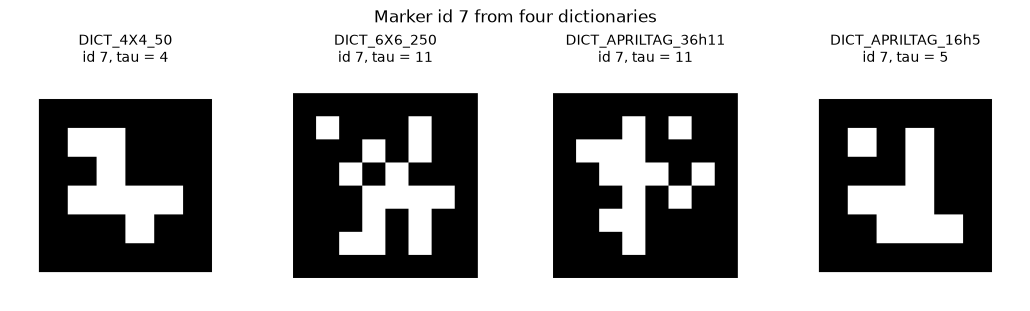

,dictionary,codes,data_bits,min_hamming,correctable_bits
0,DICT_4X4_50,50,16,4,1
1,DICT_6X6_250,250,36,11,5
2,DICT_APRILTAG_36h11,587,36,11,5
3,DICT_APRILTAG_16h5,30,16,5,2


In [2]:
# --- Generate example markers and compute each dictionary's minimum Hamming distance ---
def min_hamming(dictionary):
    # All codes as bit matrices, compared against every other code in all 4 rotations.
    n, ms = dictionary.bytesList.shape[0], dictionary.markerSize
    bits = np.stack([cv2.aruco.Dictionary_getBitsFromByteList(dictionary.bytesList[i:i + 1], ms)
                     for i in range(n)]).astype(bool)                       # (n, ms, ms)
    rots = np.stack([np.rot90(bits, k, axes=(1, 2)) for k in range(4)], 1).reshape(n, 4, -1)
    dist = (rots[:, 0][:, None, None, :] != rots[None]).sum(-1)            # (n, n, 4)
    dist[np.arange(n), np.arange(n), 0] = 10**6                             # ignore self, rot 0
    return int(dist.min())

DICTS = {"DICT_4X4_50": cv2.aruco.DICT_4X4_50, "DICT_6X6_250": cv2.aruco.DICT_6X6_250,
         "DICT_APRILTAG_36h11": cv2.aruco.DICT_APRILTAG_36h11, "DICT_APRILTAG_16h5": cv2.aruco.DICT_APRILTAG_16h5}
dict_rows, tiles, titles = [], [], []
for name, did in DICTS.items():
    d = cv2.aruco.getPredefinedDictionary(did)
    tau = min_hamming(d)
    dict_rows.append({"dictionary": name, "codes": d.bytesList.shape[0], "data_bits": d.markerSize**2,
                      "min_hamming": tau, "correctable_bits": (tau - 1) // 2})
    tiles.append(fs.marker_texture(d, 7, 0.1, cell_px=24, margin_cells=1).image)
    titles.append(f"{name}\nid 7, tau = {tau}")
fig = viz.show_images(tiles, titles, ncols=4, size=2.6, cmap="gray", suptitle="Marker id 7 from four dictionaries")
plt.show()
pd.DataFrame(dict_rows)

## 2. The marker coordinate frame

`SOLVEPNP_IPPE_SQUARE` fixes the marker frame and corner order, and `detectMarkers` returns
corners in the same order, so the two fit together without any re-ordering:

* origin at the **marker centre**, $X$ to the right, $Y$ **up**, $Z$ **out of the marker** toward the
  viewer (right-handed);
* corners: $0=(-L/2, L/2, 0)$ top-left, $1=(L/2, L/2, 0)$ top-right, $2=(L/2,-L/2,0)$ bottom-right,
  $3=(-L/2,-L/2,0)$ bottom-left, with $L$ = side of the **black border** (not of the white margin).

PnP returns $(R, t)$ with $X_\text{cam} = R\,X_\text{marker} + t$: the marker's pose in the camera
frame, $T_{\text{cam}\leftarrow\text{marker}}$. (Other libraries differ: ChArUco boards use Y down / Z into
the board, and the AprilTag C library reports Y down / Z into the tag. Always check.)

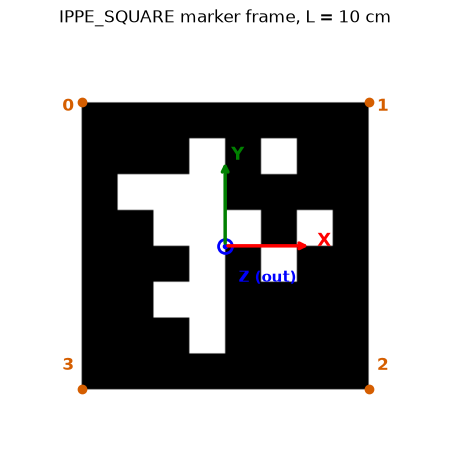

object points [m]:
 [[-0.05  0.05  0.  ]
 [ 0.05  0.05  0.  ]
 [ 0.05 -0.05  0.  ]
 [-0.05 -0.05  0.  ]]


In [3]:
# --- Draw the AprilTag 36h11 marker with its frame axes and corner indices ---
L = 0.10  # marker side (outer edge of the black border) in metres
D36 = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_APRILTAG_36h11)
tag = fs.marker_texture(D36, 7, L)
obj = fs.marker_object_points(L)
A_inv = np.linalg.inv(tag.A)  # metric (X, Y, 1) -> texture pixel
to_px = lambda X, Y: (A_inv @ np.array([X, Y, 1.0]))[:2]  # noqa: E731
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.imshow(tag.image, cmap="gray")
for i, (X, Y, _) in enumerate(obj):
    u, v = to_px(X, Y)
    ax.plot(u, v, "o", color=viz.color(5, unit=True))
    ax.annotate(f"{i}", (u, v), xytext=(-14 if X < 0 else 6, -6 if Y > 0 else 14), textcoords="offset points",
                fontsize=12, color=viz.color(5, unit=True), weight="bold")
c = to_px(0, 0)
for vec, col, lab in [((0.03, 0), "red", "X"), ((0, 0.03), "green", "Y")]:
    e = to_px(*vec)
    ax.annotate("", e, c, arrowprops=dict(arrowstyle="->", color=col, lw=2.5))
    ax.text(*e, f" {lab}", color=col, fontsize=13, weight="bold")
ax.plot(*c, "o", ms=10, mfc="none", mec="blue", mew=2)
ax.plot(*c, ".", color="blue")
ax.text(c[0] + 6, c[1] + 16, "Z (out)", color="blue", fontsize=11, weight="bold")
ax.set_title(f"IPPE_SQUARE marker frame, L = {L * 100:.0f} cm")
ax.axis("off")
plt.show()
print("object points [m]:\n", obj)

## 3. Rendering views with exact ground truth

A plane $Z=0$ maps to the image through a **homography**. With $X_\text{cam} = R X + t$ and
$X = (X, Y, 0)$:

$$
\lambda \begin{bmatrix}u\\v\\1\end{bmatrix} = K\,[\,r_1\; r_2\; r_3\; t\,]\begin{bmatrix}X\\Y\\0\\1\end{bmatrix}
= \underbrace{K\,[\,r_1\; r_2\; t\,]}_{H_\text{plane}}\begin{bmatrix}X\\Y\\1\end{bmatrix},
\qquad H = H_\text{plane}\,A,
$$

where $A$ maps marker-image pixels to metric $(X, Y)$ (note the sign flip: image rows go down,
marker $Y$ goes up). `cv2.warpPerspective` with $H$ paints the marker into the camera image.
To look like a real sensor we warp at 3x resolution and **area-average** down (anti-aliased edges),
map the print to grey levels 25-230 (paper is not perfectly black/white), then add Gaussian
optical blur ($\sigma_b = 0.6$ px) and sensor noise ($\sigma_n = 2$ grey levels).

Poses are sampled by placing the marker centre at a chosen **distance** along a random camera ray
and tilting it by a chosen **viewing angle** (angle between the marker normal and the line of sight)
about a random in-plane axis, plus a random spin about the normal. The ground-truth corners are
the exact projections $\pi(K, R, t, X_i)$.

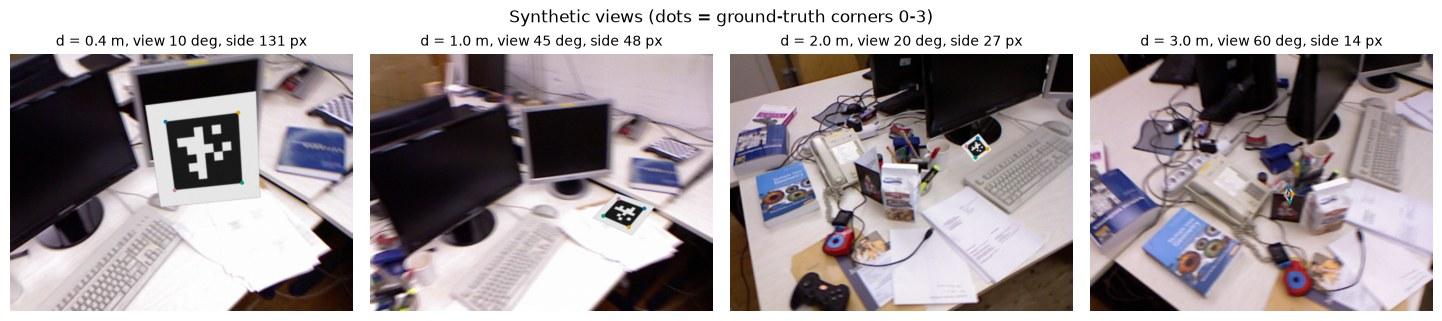

In [4]:
# --- Render four example views and overlay the ground-truth corners ---
examples = [(0.4, 10), (1.0, 45), (2.0, 20), (3.0, 60)]  # (distance [m], viewing angle [deg])
panels, titles = [], []
for k, (dist, tilt) in enumerate(examples):
    R, t = fs.sample_pose(tag, K, (W, H), dist, tilt, rng)
    img = fs.render(tag, K, R, t, BGS[k], rng=rng)
    gt, _ = fs.project(obj, K, R, t)
    vis = img[..., ::-1].copy()  # BGR -> RGB for matplotlib
    for i, (u, v) in enumerate(gt):
        cv2.circle(vis, (round(u), round(v)), 3, viz.color(i), -1, cv2.LINE_AA)
    side = np.mean(np.linalg.norm(gt - np.roll(gt, 1, 0), axis=1))
    panels.append(vis)
    titles.append(f"d = {dist} m, view {tilt} deg, side {side:.0f} px")
fig = viz.show_images(panels, titles, ncols=4, size=3.6, suptitle="Synthetic views (dots = ground-truth corners 0-3)")
viz.savefig(fig, PROJECT, "synthetic_views")
show_jpeg(fig)

## 4. Detection and corner refinement

`ArucoDetector.detectMarkers` (1) adaptively thresholds the image, (2) finds contours that are
convex quadrilaterals, (3) removes perspective by warping each quad to a square, (4) reads the bit
grid and looks the code up in the dictionary (with error correction). The quad corners from step 2
come from a polygon fit to *pixel-level contours*, so they are only accurate to about half a
pixel. `DetectorParameters.cornerRefinementMethod` adds a refinement step:

| method | what it does |
|---|---|
| `CORNER_REFINE_NONE` (**OpenCV default**) | contour polygon corners |
| `CORNER_REFINE_SUBPIX` | `cornerSubPix`: gradient-based saddle/corner refinement in a small window |
| `CORNER_REFINE_CONTOUR` | fit lines to the contour points, intersect them |
| `CORNER_REFINE_APRILTAG` | AprilTag-style edge refinement on a decimated image |

We also run the **AprilTag 3 C library** (`pupil_apriltags`, full-resolution quad detection
`quad_decimate=1.0`), which fits edges with sub-pixel gradients. It uses a different pixel origin (centre of the top-left pixel at $(0.5, 0.5)$, OpenCV
uses $(0,0)$) and a tag frame rotated relative to OpenCV's; `fs.pupil_detect` converts both
(verified in `tests/test_p07_fiducial_sim.py`). Zoom into one corner to see the differences:

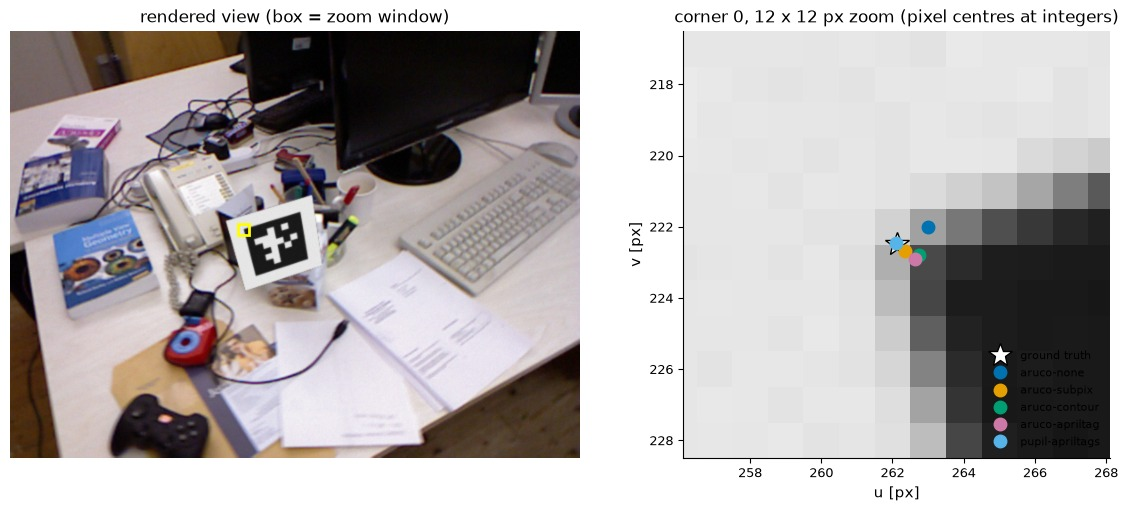

aruco-none       corner error [px]: [1.01  0.612 0.462 0.343]
aruco-subpix     corner error [px]: [0.289 0.342 0.215 0.323]
aruco-contour    corner error [px]: [0.685 0.682 0.707 0.65 ]
aruco-apriltag   corner error [px]: [0.654 0.627 0.585 0.671]
pupil-apriltags  corner error [px]: [0.038 0.033 0.006 0.023]


In [5]:
# --- Detect one view with every method and zoom into a corner ---
DETECTORS = {f"aruco-{m}": fs.make_detector(D36, m) for m in ["none", "subpix", "contour", "apriltag"]}
# quad_decimate=1.0: detect quads at full resolution (the library default 2.0 is ~4x faster
# but roughly halves the detection range for small tags).
PUPIL = pupil_apriltags.Detector(families="tag36h11", nthreads=1, quad_decimate=1.0) if HAVE_PUPIL else None

def detect_all(img, length=L, marker_id=7):
    # Corners {method: 4x2} from every detector (missing methods = not detected).
    out = {}
    for name, det in DETECTORS.items():
        found = fs.detect(det, img)
        if marker_id in found:
            out[name] = found[marker_id]
    if PUPIL is not None:
        found = fs.pupil_detect(PUPIL, img, K, length)
        if marker_id in found:
            out["pupil-apriltags"] = found[marker_id]["corners"]
    return out

R0, t0 = fs.pose_facing(tag, K, (300, 240), 0.8, tilt_deg=35, tilt_dir_deg=30, roll_deg=15)
img0 = fs.render(tag, K, R0, t0, BGS[2], rng=np.random.default_rng(1))
gt0, _ = fs.project(obj, K, R0, t0)
corners0 = detect_all(img0)
u0, v0 = gt0[0]
win = 6  # half window in pixels
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img0[..., ::-1])
axes[0].add_patch(plt.Rectangle((u0 - win, v0 - win), 2 * win, 2 * win, fill=False, ec="yellow", lw=2))
axes[0].set_title("rendered view (box = zoom window)")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(img0, cv2.COLOR_BGR2GRAY), cmap="gray", interpolation="nearest")
axes[1].set_xlim(u0 - win, u0 + win)
axes[1].set_ylim(v0 + win, v0 - win)
axes[1].plot(u0, v0, "*", ms=18, color="white", mec="black", label="ground truth")
for i, (name, c) in enumerate(corners0.items()):
    axes[1].plot(*c[0], "o", ms=9, color=viz.color(i, unit=True), label=name)
axes[1].set_title("corner 0, 12 x 12 px zoom (pixel centres at integers)")
axes[1].set_xlabel("u [px]")
axes[1].set_ylabel("v [px]")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(False)
show_jpeg(fig, quality=92)
for name, c in corners0.items():
    print(f"{name:16s} corner error [px]: {np.round(np.linalg.norm(c - gt0, axis=1), 3)}")

## 5. Pose from four corners: PnP and IPPE

**PnP** (Perspective-n-Point) finds $(R, t)$ minimising the reprojection error
$\sum_i \lVert x_i - \pi(K(RX_i + t))\rVert^2$. For a square marker, the four points are coplanar
and **IPPE** (Infinitesimal Plane-based Pose Estimation, Collins & Bartoli 2014) solves it in closed
form from the homography: it returns **two** candidate poses (the planar ambiguity, Section 9),
ordered by reprojection error. `SOLVEPNP_IPPE_SQUARE` is the variant specialised to the marker
corner layout above. `cv2.drawFrameAxes` projects the estimated frame for a visual check.

First a correctness check of the whole convention chain: with *exact* corners PnP must return the
exact pose.

In [6]:
# --- Sanity check: exact corners -> exact pose, for all solvers and 500 random poses ---
check = {m: [] for m in ["IPPE_SQUARE", "IPPE", "SQPNP", "ITERATIVE"]}
for _ in range(500):
    R, t = fs.sample_pose(tag, K, (W, H), rng.uniform(0.3, 3.0), rng.uniform(0, 70), rng)
    uv, _ = fs.project(obj, K, R, t)
    for m in check:
        res = fs.solve_marker_pose(uv, L, K, method=m)
        check[m].append((fs.rotation_error_deg(R, res.R), np.linalg.norm(res.t - t) * 1000))
pd.DataFrame({m: {"max rot err [deg]": np.max(v, 0)[0], "max trans err [mm]": np.max(v, 0)[1]}
              for m, v in check.items()}).T

,max rot err [deg],max trans err [mm]
IPPE_SQUARE,0.000002,3.460369e-10
IPPE,0.000002,1.860012e-10
SQPNP,0.000002,2.395027e-08
ITERATIVE,0.000091,2.431274e-03


Now the real thing: detected corners from the view above, pose via IPPE_SQUARE, error against
the ground truth. Translation error is split into the component **along the line of sight**
(depth) and **lateral** to it; they behave very differently.

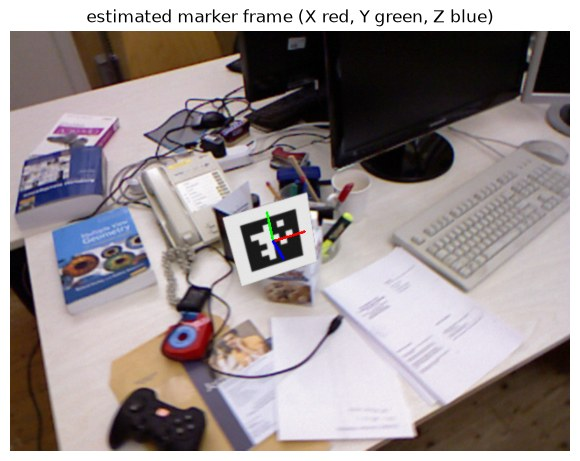

,detector,rot_err_deg,t_err_mm,depth_err_mm,lateral_err_mm,reproj_rmse_px
0,aruco-none,1.937,12.489,12.485,0.319,0.070
1,aruco-subpix,0.165,5.374,5.373,0.057,0.023
2,aruco-contour,0.292,11.994,11.994,0.056,0.031
3,aruco-apriltag,0.170,1.113,0.538,0.974,0.017
4,pupil-apriltags,0.069,0.235,0.234,0.021,0.009


In [7]:
# --- Estimate the pose from each detector's corners and draw the frame ---
rows, vis = [], img0.copy()
for name, c in corners0.items():
    res = fs.solve_marker_pose(c, L, K)
    te = fs.translation_errors(t0, res.t)
    rows.append({"detector": name, "rot_err_deg": fs.rotation_error_deg(R0, res.R),
                 "t_err_mm": 1000 * te["t_err"], "depth_err_mm": 1000 * te["t_err_depth"],
                 "lateral_err_mm": 1000 * te["t_err_lateral"], "reproj_rmse_px": res.reproj_rmse})
    if name == "pupil-apriltags" or (not HAVE_PUPIL and name == "aruco-subpix"):
        cv2.drawFrameAxes(vis, K, None, cv2.Rodrigues(res.R)[0], res.t, 0.6 * L, 2)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(vis[..., ::-1])
ax.set_title("estimated marker frame (X red, Y green, Z blue)")
ax.axis("off")
show_jpeg(fig)
pd.DataFrame(rows).round(3)

## 6. A real photo

The OpenCV ArUco tutorial ships a photo of six `DICT_6X6_250` markers printed on one sheet of
paper, together with a calibration file for the camera used in that tutorial. We do not know the
true poses, but we know a **consistency constraint**: all markers lie on one plane with their
edges aligned, so (1) all six estimated **normals** must agree, and (2) any two marker frames may
differ only by a spin about the normal that is a multiple of 90 deg (each code is printed in its own
orientation). The physical marker size is not documented; we assume $L = 5$ cm, which scales every
translation but leaves rotations unchanged.

The second detector run uses the *wrong* dictionary (`DICT_4X4_50`) on the same photo: a weak
dictionary can "find" markers in a different family's bit pattern.

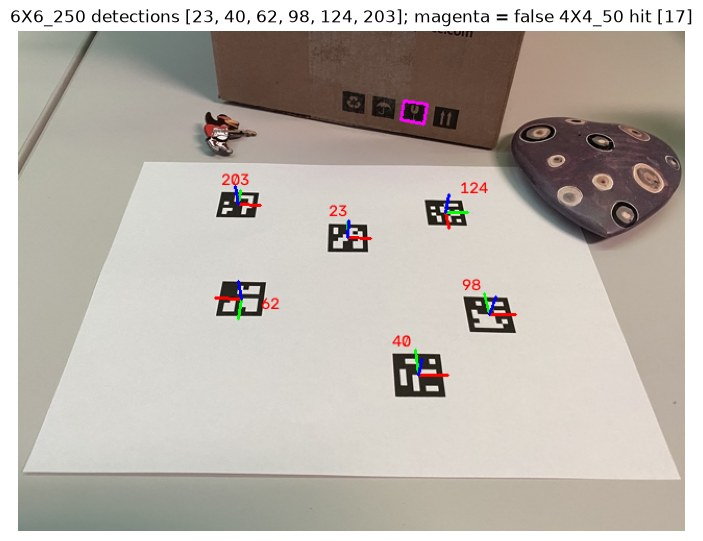

markers                             6.000
max_pairwise_rot_residual_deg       5.877
median_pairwise_rot_residual_deg    3.724
max_normal_diff_deg                 5.492
median_normal_diff_deg              3.300
reproj_rmse_px_max                  0.102
false_hits_DICT_4X4_50              1.000
dtype: float64

In [8]:
# --- Detect the six markers in the OpenCV tutorial photo and check their rotation consistency ---
photo = cv2.imread(str(cvio.data_dir(PROJECT, "singlemarkersoriginal.jpg")))
fsr = cv2.FileStorage(str(cvio.data_dir(PROJECT, "tutorial_camera_params.yml")), cv2.FILE_STORAGE_READ)
K_ph, dist_ph = fsr.getNode("camera_matrix").mat(), fsr.getNode("distortion_coefficients").mat()
L_ph = 0.05  # assumed marker size [m]
found = fs.detect(fs.make_detector(cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250), "subpix"), photo)
poses = {i: fs.solve_marker_pose(c, L_ph, K_ph, dist_ph) for i, c in sorted(found.items())}
vis = photo.copy()
for i, p in poses.items():
    cv2.drawFrameAxes(vis, K_ph, dist_ph, cv2.Rodrigues(p.R)[0], p.t, 0.6 * L_ph, 2)
    cv2.putText(vis, str(i), (int(found[i][0, 0]), int(found[i][0, 1]) - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1, cv2.LINE_AA)
wrong = fs.detect(fs.make_detector(cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_50), "subpix"), photo)
for c in wrong.values():
    cv2.polylines(vis, [c.astype(np.int32)], True, (255, 0, 255), 2)
ids = list(poses)
RZ90 = [cv2.Rodrigues(np.array([0.0, 0.0, k * np.pi / 2]))[0] for k in range(4)]  # spins about the normal
pair = [min(fs.rotation_error_deg(poses[a].R @ Rz, poses[b].R) for Rz in RZ90)   # residual after the best 90-deg spin
        for k, a in enumerate(ids) for b in ids[k + 1:]]
normal_spread = [fs.normal_error_deg(poses[a].R, poses[b].R) for k, a in enumerate(ids) for b in ids[k + 1:]]
fig, ax = plt.subplots(figsize=(7, 5.3))
ax.imshow(vis[..., ::-1])
ax.set_title(f"6X6_250 detections {ids}; magenta = false 4X4_50 hit {list(wrong)}")
ax.axis("off")
show_jpeg(fig)
photo_stats = {"markers": len(ids), "max_pairwise_rot_residual_deg": max(pair),
               "median_pairwise_rot_residual_deg": float(np.median(pair)), "max_normal_diff_deg": max(normal_spread),
               "median_normal_diff_deg": float(np.median(normal_spread)),
               "reproj_rmse_px_max": max(p.reproj_rmse for p in poses.values()),
               "false_hits_DICT_4X4_50": len(wrong)}
pd.Series(photo_stats).round(3)

## 7. Corner accuracy: noise versus *bias*

Section 4 hinted that some detectors are off in a systematic direction. Over 80 random views
(distance 0.4-1.5 m, viewing angle 0-60 deg) we measure, per method, the mean corner offset
$(\bar{\Delta u}, \bar{\Delta v})$, the mean **radial** offset (positive = corner pushed away from the
marker centre) and the RMS error, plus the detector run time.

Why the radial component matters: the marker's apparent size $w \approx fL/z$ fixes its distance.
If every corner is pulled inward by $\delta r$, the diagonal shrinks by $2\delta r$ and

$$\frac{\delta z}{z} \approx -\frac{\sqrt{2}\,\delta r}{w},$$

so a $-0.5$ px bias on a 50 px marker (1 m away here) over-estimates the distance by about 1.4 %,
i.e. 14 mm, no matter how many frames you average.

In [9]:
# --- Corner bias / RMS / timing for every detection method over 80 random views ---
bias_rows = {name: [] for name in [*DETECTORS, "pupil-apriltags"][: len(DETECTORS) + HAVE_PUPIL]}
times = {name: [] for name in bias_rows}
for _ in range(80):
    R, t = fs.sample_pose(tag, K, (W, H), rng.uniform(0.4, 1.5), rng.uniform(0, 60), rng)
    img = fs.render(tag, K, R, t, BGS[rng.integers(len(BGS))], rng=rng)
    gt, _ = fs.project(obj, K, R, t)
    radial_dir = (gt - gt.mean(0)) / np.linalg.norm(gt - gt.mean(0), axis=1, keepdims=True)
    for name in bias_rows:
        t_start = time.perf_counter()
        if name == "pupil-apriltags":
            found = {k: v["corners"] for k, v in fs.pupil_detect(PUPIL, img, K, L).items()}
        else:
            found = fs.detect(DETECTORS[name], img)
        times[name].append(1000 * (time.perf_counter() - t_start))
        if 7 in found:
            e = found[7] - gt
            bias_rows[name].append(np.column_stack([e, (e * radial_dir).sum(1)]))
corner_df = pd.DataFrame([
    {"method": name, "detected": f"{len(v)}/80", "mean_du_px": np.concatenate(v)[:, 0].mean(),
     "mean_dv_px": np.concatenate(v)[:, 1].mean(), "mean_radial_px": np.concatenate(v)[:, 2].mean(),
     "rms_px": np.sqrt((np.concatenate(v)[:, :2] ** 2).sum(1).mean()), "time_ms": np.median(times[name])}
    for name, v in bias_rows.items()]).set_index("method")
corner_df.round(3)

,detected,mean_du_px,mean_dv_px,mean_radial_px,rms_px,time_ms
method,,,,,,
aruco-none,80/80,-0.010,-0.004,-0.518,0.751,2.611
aruco-subpix,80/80,0.003,0.015,-0.256,0.371,2.433
aruco-contour,80/80,-0.009,0.002,-0.688,0.717,2.479
aruco-apriltag,80/80,0.448,0.449,-0.012,0.649,22.364
pupil-apriltags,80/80,0.001,-0.002,-0.001,0.060,11.620


Reading the table: `none` and `contour` corners sit about half a pixel *inside* the marker (the
contour runs along the inner edge of the dark pixels), `subpix` removes about half of that, OpenCV's
`apriltag` refinement has almost no radial bias but a constant shift along $+u,+v$ (a pixel-origin
convention offset, which mostly moves the pose sideways) and is by far the slowest, and the
AprilTag 3 library (after our half-pixel correction) is the most accurate. Timings are single-thread
CPU times measured while the machine was shared with other jobs, so compare them only relative to
each other.

## 8. Accuracy sweeps

Each trial renders one random view and runs every detector on the *same* image; the pose comes from
IPPE_SQUARE on the detected corners. We sweep one factor at a time (40 trials per value):

| sweep | values | other factors |
|---|---|---|
| distance | 0.25-5 m | viewing angle uniform 0-60 deg |
| viewing angle | 0-75 deg | distance 1 m |
| image noise $\sigma_n$ | 0-20 grey levels | 1 m, 0-60 deg |
| optical blur $\sigma_b$ | 0-3 px | 1 m, 0-60 deg |

A trial counts as a *flip* when IPPE's second-best candidate is closer to the ground truth than the
returned one (Section 9).

In [10]:
# --- Run the four sweeps (about 1200 renders, ~1-2 minutes on the CPU) ---
def trial(dist, tilt, noise=2.0, blur=0.6):
    R, t = fs.sample_pose(tag, K, (W, H), dist, tilt, rng)
    img = fs.render(tag, K, R, t, BGS[rng.integers(len(BGS))], blur_sigma=blur, noise_sigma=noise, rng=rng)
    gt, _ = fs.project(obj, K, R, t)
    side_px = np.mean(np.linalg.norm(gt - np.roll(gt, 1, 0), axis=1))
    rows = []
    for name, c in detect_all(img).items():
        res = fs.solve_marker_pose(c, L, K)
        alt = res.candidates[1][0] if len(res.candidates) > 1 else res.R
        rows.append({"detector": name, "rot_err": fs.rotation_error_deg(R, res.R),
                     **fs.translation_errors(t, res.t), "dist": dist, "tilt": tilt,
                     "flip": fs.rotation_error_deg(R, res.R) > fs.rotation_error_deg(R, alt)})
    return rows, side_px

def run_sweep(param, values, n=40, **fixed):
    out, sides = [], []
    for val in values:
        for _ in range(n):
            kw = dict(fixed)
            kw[param] = val
            if "tilt" not in kw:
                kw["tilt"] = rng.uniform(0, 60)
            rows, side = trial(**kw)
            sides.append({param: val, "side_px": side})
            for name in [*DETECTORS, "pupil-apriltags"][: len(DETECTORS) + HAVE_PUPIL]:  # misses count too
                found = [r for r in rows if r["detector"] == name]
                out.append({param: val, "detector": name, "detected": bool(found), "side_px": side,
                            **(found[0] if found else {})})
    return pd.DataFrame(out)

t_start = time.perf_counter()
sweeps = {
    "dist": run_sweep("dist", [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]),
    "tilt": run_sweep("tilt", [0, 5, 10, 20, 30, 40, 50, 60, 70, 75], dist=1.0),
    "noise": run_sweep("noise", [0.0, 2.0, 5.0, 10.0, 20.0], dist=1.0),
    "blur": run_sweep("blur", [0.0, 0.6, 1.2, 2.0, 3.0], dist=1.0),
}
print(f"{sum(len(s) for s in sweeps.values())} detector runs in {time.perf_counter() - t_start:.0f} s")

def summarise(df, param):
    g = df.groupby(["detector", param])
    return g.agg(det_rate=("detected", "mean"), side_px=("side_px", "mean"),
                 rot_med=("rot_err", "median"), rot_p90=("rot_err", lambda x: np.nanpercentile(x, 90) if x.notna().any() else np.nan),
                 t_med_mm=("t_err", lambda x: 1000 * x.median()), depth_med_mm=("t_err_depth", lambda x: 1000 * x.median()),
                 lat_med_mm=("t_err_lateral", lambda x: 1000 * x.median()),
                 flip_rate=("flip", lambda x: x.dropna().astype(float).mean())).reset_index()

summ = {k: summarise(v, k) for k, v in sweeps.items()}
summ["dist"].pivot(index="dist", columns="detector", values=["det_rate", "t_med_mm"]).round(3)

6000 detector runs in 69 s


det_rate                                                        \
detector aruco-apriltag aruco-contour aruco-none aruco-subpix pupil-apriltags   
dist                                                                            
0.25              1.000         1.000      1.000        1.000           1.000   
0.50              1.000         1.000      1.000        1.000           1.000   
0.75              1.000         1.000      1.000        1.000           1.000   
1.00              1.000         1.000      1.000        1.000           1.000   
1.50              1.000         1.000      1.000        1.000           1.000   
2.00              1.000         1.000      1.000        1.000           1.000   
2.50              0.900         1.000      1.000        1.000           1.000   
3.00              0.475         0.900      0.900        0.900           0.900   
4.00              0.000         0.525      0.525        0.525           0.475   
5.00              0.000         0.075      0.075        0.075           0.025   

               t_med_mm                                                        
detector aruco-apriltag aruco-contour aruco-none aruco-subpix pupil-apriltags  
dist                                                                           
0.25              0.302         1.301      0.911        0.272           0.015  
0.50              0.610         5.020      3.591        1.267           0.135  
0.75              0.933        10.562      8.932        3.601           0.206  
1.00              1.277        17.928     11.411        6.125           0.335  
1.50              2.498        40.962     34.729       22.127           1.109  
2.00              5.528        75.376     61.744       38.288           2.371  
2.50              7.823       122.359     96.228       53.890           7.220  
3.00             16.191       184.242    140.972       78.458          17.387  
4.00                NaN       306.195    229.601      135.706          29.487  
5.00                NaN       438.002    231.512      172.338          70.558

Viewing angle: rotation error is worst **head-on** (a frontal square changes very little in the
image when tilted slightly, so the tilt is poorly observable) and improves with oblique views,
until foreshortening makes the marker too thin to decode.

In [11]:
# --- Viewing-angle sweep: rotation error and flip rate per detector ---
summ["tilt"].pivot(index="tilt", columns="detector", values=["rot_med", "flip_rate"]).round(3)

rot_med                                                        \
detector aruco-apriltag aruco-contour aruco-none aruco-subpix pupil-apriltags   
tilt                                                                            
0                 3.138         3.443      8.694        3.138           2.843   
5                 0.835         1.226      5.260        0.922           0.848   
10                0.447         0.537      3.523        0.580           0.376   
20                0.290         0.366      1.719        0.278           0.185   
30                0.185         0.309      1.369        0.215           0.112   
40                0.163         0.368      0.868        0.248           0.095   
50                0.160         0.437      0.901        0.250           0.091   
60                0.170         0.540      0.911        0.394           0.094   
70                0.181         0.677      0.816        0.712           0.237   
75                0.241         0.661      0.770        0.810           0.337   

              flip_rate                                                        
detector aruco-apriltag aruco-contour aruco-none aruco-subpix pupil-apriltags  
tilt                                                                           
0                  0.50         0.125       0.20         0.15           0.125  
5                  0.05         0.050       0.10         0.00           0.000  
10                 0.00         0.000       0.05         0.00           0.000  
20                 0.00         0.000       0.00         0.00           0.000  
30                 0.00         0.000       0.00         0.00           0.000  
40                 0.00         0.000       0.00         0.00           0.000  
50                 0.00         0.000       0.00         0.00           0.000  
60                 0.00         0.000       0.00         0.00           0.000  
70                 0.00         0.000       0.00         0.00           0.000  
75                 0.00         0.000       0.00         0.00           0.000

Image quality: noise and blur sweeps at 1 m (median translation error in mm, detection rate).

In [12]:
# --- Noise and blur sweeps ---
pd.concat({k: summ[k].pivot(index=k, columns="detector", values=["det_rate", "t_med_mm"]) for k in ["noise", "blur"]}).round(3)

det_rate                                        \
detector   aruco-apriltag aruco-contour aruco-none aruco-subpix   
noise 0.0             1.0         1.000      1.000        1.000   
      2.0             1.0         1.000      1.000        1.000   
      5.0             1.0         1.000      1.000        1.000   
      10.0            1.0         1.000      1.000        1.000   
      20.0            1.0         1.000      1.000        1.000   
blur  0.0             1.0         1.000      1.000        1.000   
      0.6             1.0         1.000      1.000        1.000   
      1.2             1.0         1.000      1.000        1.000   
      2.0             1.0         0.975      0.975        0.975   
      3.0             0.6         0.650      0.650        0.650   

                                 t_med_mm                           \
detector   pupil-apriltags aruco-apriltag aruco-contour aruco-none   
noise 0.0            1.000          1.333        20.354     13.501   
      2.0            1.000          1.303        18.061     13.833   
      5.0            1.000          1.347        17.835     13.843   
      10.0           1.000          1.343        19.541     12.492   
      20.0           1.000          1.413        16.995     13.579   
blur  0.0            1.000          1.250        19.357     13.179   
      0.6            1.000          1.337        18.896     11.277   
      1.2            1.000          1.480        16.653     14.811   
      2.0            1.000          1.889        17.158     20.336   
      3.0            0.475          2.435         6.060     24.361   

                                         
detector   aruco-subpix pupil-apriltags  
noise 0.0         6.316           0.488  
      2.0         6.526           0.511  
      5.0         6.231           0.547  
      10.0        6.204           0.762  
      20.0        7.398           0.823  
blur  0.0         4.397           0.551  
      0.6         6.478           0.438  
      1.2        11.172           0.518  
      2.0        20.730           0.674  
      3.0        22.661           3.212

### Isolating PnP: controlled corner noise

To separate the solver from the detector, skip rendering: project the true corners and add
i.i.d. Gaussian noise $\mathcal{N}(0, \sigma^2)$ to each coordinate (1 m, 30 deg viewing angle,
500 trials per $\sigma$). Compared solvers: `IPPE_SQUARE`, generic planar `IPPE`, `SQPNP`
(globally optimal for any point layout), `ITERATIVE` (DLT/homography init + Levenberg-Marquardt) and
`IPPE_SQUARE` followed by `solvePnPRefineLM`.

In [13]:
# --- PnP solver comparison under controlled corner noise ---
SOLVERS = {"IPPE_SQUARE": ("IPPE_SQUARE", False), "IPPE": ("IPPE", False), "SQPNP": ("SQPNP", False),
           "ITERATIVE": ("ITERATIVE", False), "IPPE_SQUARE+LM": ("IPPE_SQUARE", True)}
SIGMAS = [0.1, 0.2, 0.5, 1.0, 2.0]
pnp_rows = []
for sigma in SIGMAS:
    for _ in range(500):
        R, t = fs.sample_pose(tag, K, (W, H), 1.0, 30.0, rng)
        uv = fs.project(obj, K, R, t)[0] + rng.normal(0, sigma, (4, 2))
        for name, (method, lm) in SOLVERS.items():
            res = fs.solve_marker_pose(uv, L, K, method=method, refine_lm=lm)
            pnp_rows.append({"sigma_px": sigma, "solver": name, "rot_err": fs.rotation_error_deg(R, res.R),
                             **fs.translation_errors(t, res.t)})
pnp_df = pd.DataFrame(pnp_rows)
pnp_summary = pnp_df.groupby(["solver", "sigma_px"]).agg(
    rot_med_deg=("rot_err", "median"), t_med_mm=("t_err", lambda x: 1000 * x.median()),
    depth_med_mm=("t_err_depth", lambda x: 1000 * x.median()), lateral_med_mm=("t_err_lateral", lambda x: 1000 * x.median()))
pnp_summary.unstack("solver")["rot_med_deg"].round(3)

solver,IPPE,IPPE_SQUARE,IPPE_SQUARE+LM,ITERATIVE,SQPNP
sigma_px,,,,,
0.1,0.354,0.354,0.346,0.346,0.343
0.2,0.694,0.694,0.683,0.683,0.683
0.5,1.754,1.754,1.760,1.760,1.762
1.0,3.480,3.480,3.527,3.567,3.566
2.0,9.208,9.208,9.260,9.316,9.334


## 9. The planar pose ambiguity

For a small or distant plane, perspective is weak and the image is almost unchanged if the
plane's normal is **reflected about the line of sight**: tilting the marker by $+\theta$ or
$-\theta$ produces nearly the same quadrilateral. IPPE makes this explicit by returning both
poses with their reprojection errors $e_1 \le e_2$. When $e_2/e_1 \approx 1$ the choice is
decided by noise and can **flip**. The two candidates share (almost) the same translation but their
normals differ by about $2\theta$.

Remedies used in practice: track over time and pick the candidate closest to the previous pose
(Exercise 2), use several coplanar markers or a board (more spread-out points, notebook 03),
make markers larger, or view them obliquely.

Below we find a flipped case among near-frontal, distant noisy renders and draw both candidates.

flipped example found: True (after 1 renders)


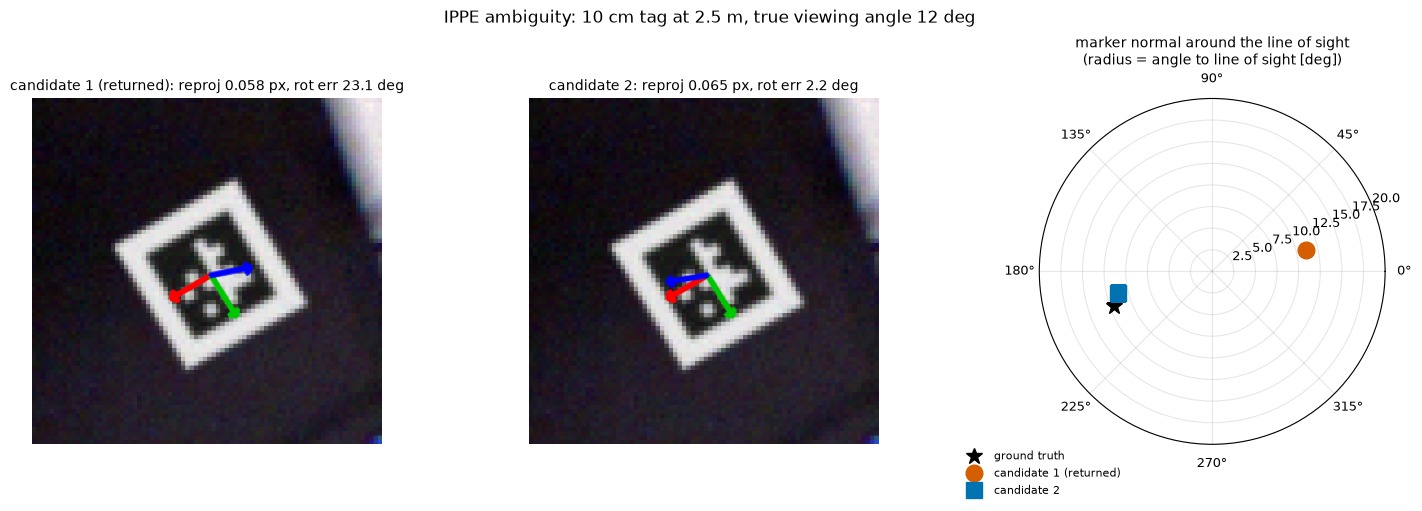

,candidate,reproj_px,rot_err_deg,normal_vs_sight_deg,t_err_mm
0,1,0.058,23.140,11.160,46.542
1,2,0.065,2.174,11.162,46.470


In [14]:
# --- Find a near-frontal view where IPPE returns the wrong branch and draw both candidates ---
amb_rng = np.random.default_rng(3)
flipped = False
for attempt in range(500):
    R, t = fs.sample_pose(tag, K, (W, H), 2.5, 12.0, amb_rng)
    img = fs.render(tag, K, R, t, BGS[attempt % len(BGS)], noise_sigma=4.0, rng=amb_rng)
    found = fs.detect(DETECTORS["aruco-subpix"], img)
    if 7 not in found:
        continue
    res = fs.solve_marker_pose(found[7], L, K)
    errs = [fs.rotation_error_deg(R, c[0]) for c in res.candidates]
    if errs[0] > errs[1] + 5:
        flipped = True
        break
print(f"flipped example found: {flipped} (after {attempt + 1} renders)")
# Left/middle: 4x zoom with each candidate frame drawn at the zoomed resolution (Z axis 2L long).
# Right: the normals seen along the line of sight (polar angle = angle to the line of sight).
Z = 4
x0, y0 = found[7].min(0).astype(int) - 25
x1, y1 = found[7].max(0).astype(int) + 25
K_crop = fs.scaled_K(K, Z)
K_crop[0, 2] -= Z * x0
K_crop[1, 2] -= Z * y0
fig = plt.figure(figsize=(15, 5))
for k, (Rc, tc, e) in enumerate(res.candidates):
    crop = cv2.resize(img[y0:y1, x0:x1], None, fx=Z, fy=Z, interpolation=cv2.INTER_NEAREST)
    pts = np.array([[0, 0, 0], [0.5 * L, 0, 0], [0, 0.5 * L, 0], [0, 0, 2 * L]])
    uv = fs.project(pts, K_crop, Rc, tc)[0].round().astype(int)
    for a, col in zip(range(1, 4), [(0, 0, 255), (0, 200, 0), (255, 0, 0)]):  # BGR: X red, Y green, Z blue
        cv2.arrowedLine(crop, tuple(uv[0]), tuple(uv[a]), col, 3, cv2.LINE_AA, tipLength=0.15)
    ax = fig.add_subplot(1, 3, k + 1)
    ax.imshow(crop[..., ::-1])
    ax.set_title(f"candidate {k + 1}{' (returned)' if k == 0 else ''}: reproj {e:.3f} px, rot err {errs[k]:.1f} deg", fontsize=10)
    ax.axis("off")
los = -t / np.linalg.norm(t)  # unit vector from the marker towards the camera
e1 = np.cross(los, [0.0, 1.0, 0.0])
e1 /= np.linalg.norm(e1)
e2 = np.cross(los, e1)
ax = fig.add_subplot(1, 3, 3, projection="polar")
for n, lab, mk, col in [(R[:, 2], "ground truth", "*", "black"), (res.candidates[0][0][:, 2], "candidate 1 (returned)", "o", viz.color(5, unit=True)),
                        (res.candidates[1][0][:, 2], "candidate 2", "s", viz.color(0, unit=True))]:
    ax.plot(np.arctan2(n @ e2, n @ e1), np.degrees(np.arccos(np.clip(n @ los, -1, 1))), mk, ms=12, color=col, label=lab)
ax.set_rmax(20)
ax.set_title("marker normal around the line of sight\n(radius = angle to line of sight [deg])", fontsize=10)
ax.legend(loc="lower left", bbox_to_anchor=(-0.25, -0.18), fontsize=8)
fig.suptitle("IPPE ambiguity: 10 cm tag at 2.5 m, true viewing angle 12 deg")
viz.savefig(fig, PROJECT, "ippe_ambiguity")
show_jpeg(fig, quality=92)
amb_table = pd.DataFrame([{"candidate": k + 1, "reproj_px": e, "rot_err_deg": errs[k],
                           "normal_vs_sight_deg": np.degrees(np.arccos(Rc[:, 2] @ (-tc / np.linalg.norm(tc)))),
                           "t_err_mm": 1000 * np.linalg.norm(tc - t)} for k, (Rc, tc, e) in enumerate(res.candidates)])
amb_table.round(3)

How often does it flip? Using exact projections plus $\sigma = 0.5$ px corner noise (no rendering,
so this isolates the geometry), we measure the flip rate on a grid of distances and viewing angles
for a 10 cm marker.

In [15]:
# --- Flip-rate map over distance x viewing angle (IPPE_SQUARE, sigma = 0.5 px corner noise) ---
FLIP_D = [0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
FLIP_T = [0, 5, 10, 15, 20, 30, 45]
flip_map = np.zeros((len(FLIP_T), len(FLIP_D)))
for i, tilt in enumerate(FLIP_T):
    for j, dist in enumerate(FLIP_D):
        flips = 0
        for _ in range(300):
            R, t = fs.sample_pose(tag, K, (W, H), dist, tilt, rng)
            res = fs.solve_marker_pose(fs.project(obj, K, R, t)[0] + rng.normal(0, 0.5, (4, 2)), L, K)
            flips += fs.rotation_error_deg(R, res.candidates[0][0]) > fs.rotation_error_deg(R, res.candidates[1][0])
        flip_map[i, j] = flips / 300
pd.DataFrame(flip_map, index=pd.Index(FLIP_T, name="view angle [deg]"),
             columns=pd.Index(FLIP_D, name="distance [m]")).round(2)

distance [m],0.5,1.0,1.5,2.0,3.0,4.0
view angle [deg],,,,,,
0,0.24,0.22,0.26,0.27,0.24,0.26
5,0.09,0.34,0.49,0.45,0.51,0.54
10,0.00,0.20,0.33,0.44,0.49,0.45
15,0.00,0.07,0.24,0.38,0.45,0.48
20,0.00,0.04,0.20,0.29,0.42,0.47
30,0.00,0.00,0.13,0.26,0.40,0.44
45,0.00,0.01,0.08,0.16,0.43,0.42


## Results

All numbers come from the synthetic benchmark above (TUM fr1 camera model, 640x480, 10 cm
AprilTag 36h11, 40 trials per sweep value) and run on the CPU.

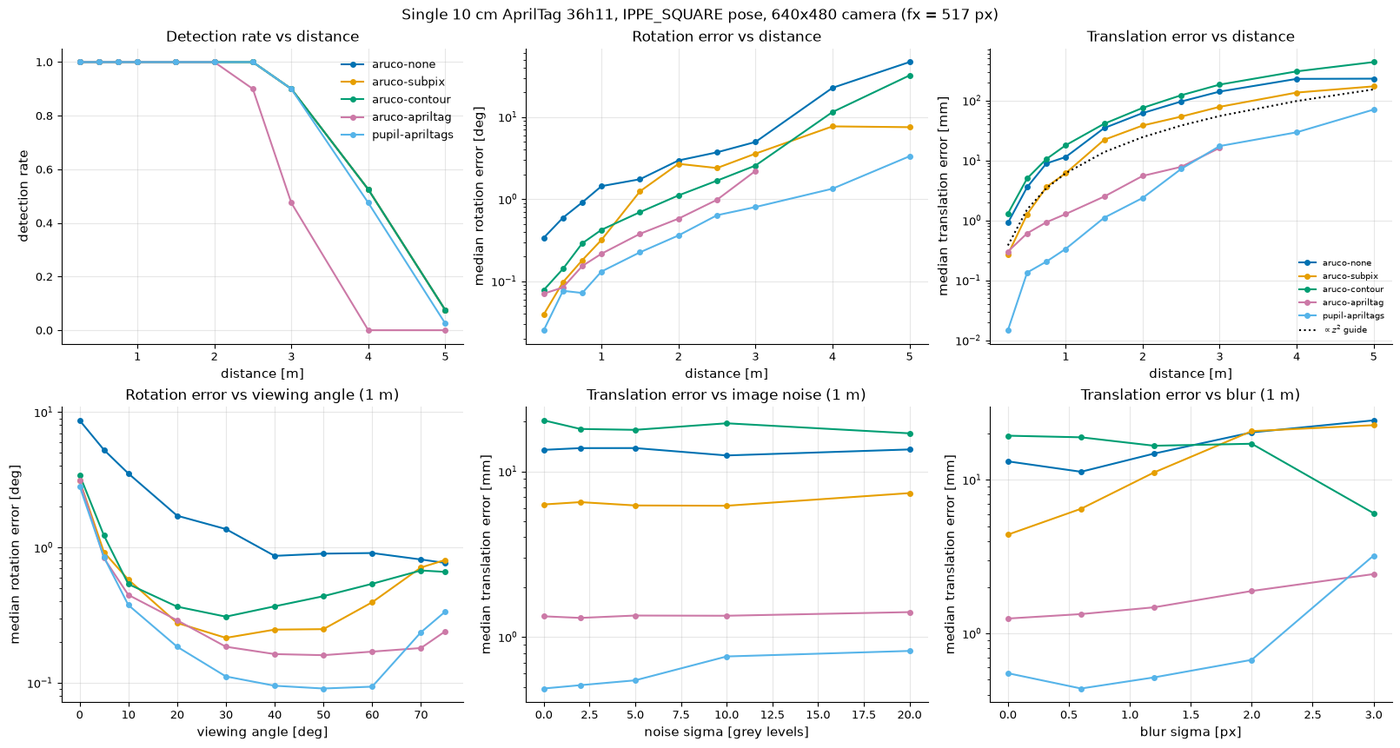

In [16]:
# --- Figure: accuracy vs distance / viewing angle / noise / blur for every detector ---
def at(key, det, param, val, col):
    # One summary value, e.g. the median translation error of a detector at 1 m.
    s = summ[key]
    return float(s[(s.detector == det) & (s[param] == val)][col].iloc[0])

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
names = list(bias_rows)
def plot_metric(ax, key, param, metric, ylabel, title, logy=False, scale=1.0):
    for i, name in enumerate(names):
        d = summ[key][summ[key].detector == name]
        ax.plot(d[param], d[metric] * scale, "o-", color=viz.color(i, unit=True), label=name, ms=4)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if logy:
        ax.set_yscale("log")
plot_metric(axes[0, 0], "dist", "dist", "det_rate", "detection rate", "Detection rate vs distance")
plot_metric(axes[0, 1], "dist", "dist", "rot_med", "median rotation error [deg]", "Rotation error vs distance", logy=True)
plot_metric(axes[0, 2], "dist", "dist", "t_med_mm", "median translation error [mm]", "Translation error vs distance", logy=True)
plot_metric(axes[1, 0], "tilt", "tilt", "rot_med", "median rotation error [deg]", "Rotation error vs viewing angle (1 m)", logy=True)
plot_metric(axes[1, 1], "noise", "noise", "t_med_mm", "median translation error [mm]", "Translation error vs image noise (1 m)", logy=True)
plot_metric(axes[1, 2], "blur", "blur", "t_med_mm", "median translation error [mm]", "Translation error vs blur (1 m)", logy=True)
for ax, xl in zip(axes.flat, ["distance [m]", "distance [m]", "distance [m]", "viewing angle [deg]",
                              "noise sigma [grey levels]", "blur sigma [px]"]):
    ax.set_xlabel(xl)
anchor = at("dist", "aruco-subpix", "dist", 1.0, "t_med_mm")  # guide line through subpix @ 1 m
z = np.array(sorted(summ["dist"]["dist"].unique()))
axes[0, 2].plot(z, anchor * z**2, "k:", label=r"$\propto z^2$ guide")
axes[0, 0].legend()
axes[0, 2].legend(fontsize=7)
fig.suptitle("Single 10 cm AprilTag 36h11, IPPE_SQUARE pose, 640x480 camera (fx = 517 px)")
viz.savefig(fig, PROJECT, "marker_accuracy")
plt.show()

PnP solvers under controlled noise, and the flip-rate map:

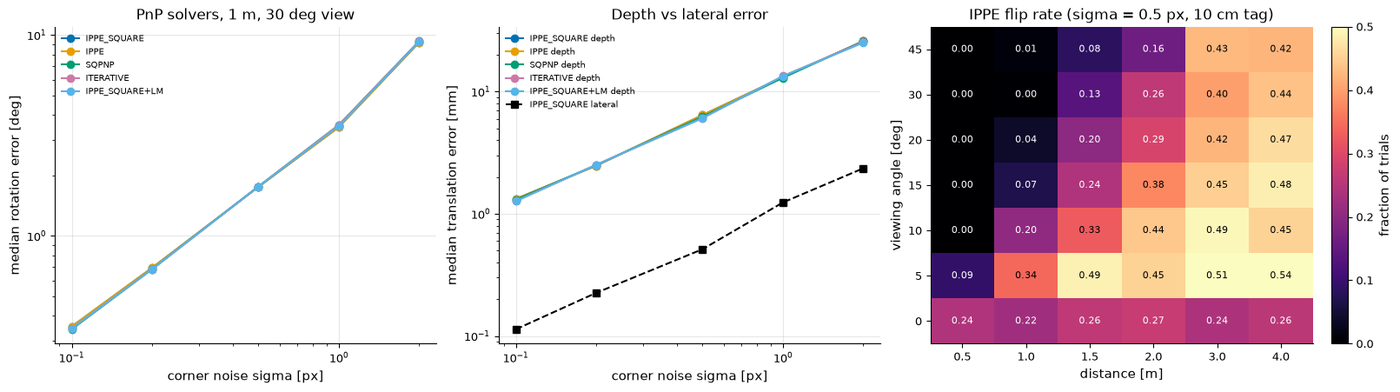

In [17]:
# --- Figure: PnP solver comparison + IPPE flip-rate map ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for i, solver in enumerate(SOLVERS):
    d = pnp_summary.loc[solver]
    axes[0].plot(d.index, d.rot_med_deg, "o-", color=viz.color(i, unit=True), label=solver)
    axes[1].plot(d.index, d.depth_med_mm, "o-", color=viz.color(i, unit=True), label=f"{solver} depth")
d = pnp_summary.loc["IPPE_SQUARE"]
axes[1].plot(d.index, d.lateral_med_mm, "s--", color="black", label="IPPE_SQUARE lateral")
for ax in axes[:2]:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("corner noise sigma [px]")
    ax.legend(fontsize=7)
axes[0].set_ylabel("median rotation error [deg]")
axes[0].set_title("PnP solvers, 1 m, 30 deg view")
axes[1].set_ylabel("median translation error [mm]")
axes[1].set_title("Depth vs lateral error")
im = axes[2].imshow(flip_map, origin="lower", cmap="magma", vmin=0, vmax=0.5, aspect="auto")
axes[2].set_xticks(range(len(FLIP_D)), FLIP_D)
axes[2].set_yticks(range(len(FLIP_T)), FLIP_T)
axes[2].set_xlabel("distance [m]")
axes[2].set_ylabel("viewing angle [deg]")
axes[2].set_title("IPPE flip rate (sigma = 0.5 px, 10 cm tag)")
axes[2].grid(False)
for (i, j), v in np.ndenumerate(flip_map):
    axes[2].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v < 0.3 else "black")
fig.colorbar(im, ax=axes[2], label="fraction of trials")
viz.savefig(fig, PROJECT, "pnp_noise_ambiguity")
plt.show()

Summary per detector. *Range* is the largest distance in the sweep with at least 90 % detection;
errors are medians at 1 m (viewing angle 0-60 deg). Saved to `results/fiducial_pose.json`.

In [18]:
# --- Summary table + results JSON ---
summary_rows = []
for name in names:
    s = summ["dist"][summ["dist"].detector == name]
    summary_rows.append({
        "detector": name,
        "range_90pct_m": float(s[s.det_rate >= 0.9]["dist"].max()),
        "rot_med_deg@1m": at("dist", name, "dist", 1.0, "rot_med"),
        "t_med_mm@1m": at("dist", name, "dist", 1.0, "t_med_mm"),
        "depth_med_mm@1m": at("dist", name, "dist", 1.0, "depth_med_mm"),
        "lateral_med_mm@1m": at("dist", name, "dist", 1.0, "lat_med_mm"),
        "t_med_mm@2m": at("dist", name, "dist", 2.0, "t_med_mm"),
        "rot_med_deg@frontal": at("tilt", name, "tilt", 0, "rot_med"),
        "mean_radial_bias_px": corner_df.loc[name, "mean_radial_px"],
        "corner_rms_px": corner_df.loc[name, "rms_px"],
        "time_ms": corner_df.loc[name, "time_ms"],
    })
summary = pd.DataFrame(summary_rows).set_index("detector")
cvio.save_json({"setup": "synthetic renders, TUM fr1 camera 640x480, 10 cm AprilTag 36h11, 40 trials/value, CPU",
                "summary": summary.round(4).reset_index().to_dict(orient="records"),
                "corner_bias": corner_df.round(4).reset_index().to_dict(orient="records"),
                "pnp_noise": pnp_summary.round(4).reset_index().to_dict(orient="records"),
                "flip_map": {"dist_m": FLIP_D, "tilt_deg": FLIP_T, "rate": flip_map.round(4).tolist()},
                "real_photo": photo_stats}, PROJ_DIR / "results" / "fiducial_pose.json")
summary.round(3)

,range_90pct_m,rot_med_deg@1m,t_med_mm@1m,depth_med_mm@1m,lateral_med_mm@1m,t_med_mm@2m,rot_med_deg@frontal,mean_radial_bias_px,corner_rms_px,time_ms
detector,,,,,,,,,,
aruco-none,3.0,1.440,11.411,11.394,0.346,61.744,8.694,-0.518,0.751,2.611
aruco-subpix,3.0,0.319,6.125,6.124,0.064,38.288,3.138,-0.256,0.371,2.433
aruco-contour,3.0,0.424,17.928,17.927,0.058,75.376,3.443,-0.688,0.717,2.479
aruco-apriltag,2.5,0.217,1.277,0.468,1.167,5.528,3.138,-0.012,0.649,22.364
pupil-apriltags,3.0,0.132,0.335,0.330,0.027,2.371,2.843,-0.001,0.060,11.620


### Takeaways

* **Corner bias dominates.** OpenCV's default `CORNER_REFINE_NONE` puts the corners about half a
  pixel inside the marker; at 1 m that is a median translation error of about 11 mm, almost all of
  it along the line of sight, and it does not average out over frames. `SUBPIX` halves it; OpenCV's
  `APRILTAG` refinement removes the radial bias but adds a constant half-pixel shift; the AprilTag 3
  library (with the half-pixel origin fix) is the most accurate here (sub-millimetre at 1 m,
  corner RMS well below 0.1 px). **Always set `cornerRefinementMethod`.**
* **Noise hardly matters; blur and bias do.** Up to 20 grey levels of noise the errors barely move,
  because edge and corner fits average many pixels. Blur, in contrast, pushes the `SUBPIX` corners
  further inwards (its error grows about fivefold from 0 to 3 px blur).
* **Error grows roughly with $z^2$.** The marker's pixel size shrinks as $1/z$, so a fixed pixel
  error costs $\propto z^2$ in depth, and depth (along the line of sight) is about ten times less
  accurate than the lateral position. A 10 cm tag on this 640x480 camera is detected reliably to
  about 3 m (17 px side). Only $L/z$, the side length in pixels, matters: for range, print bigger.
* **Frontal views are the worst for rotation.** The median rotation error is about 3 deg head-on
  versus 0.1-0.5 deg at 30-60 deg, and IPPE's two candidates compete (flip rates of 20-50 % for small,
  distant or near-frontal tags). Use temporal priors, several markers or boards (notebook 03).
* **Solvers are interchangeable.** With the same corners, IPPE_SQUARE, IPPE, SQPNP, ITERATIVE and
  LM-refined IPPE give the same accuracy; the work is in unbiased corners.
* **Real photo:** the six coplanar markers in the OpenCV tutorial photo agree to within about
  6 deg (normals and rotations after removing the 90 deg print orientations), consistent with
  the near-frontal ambiguity of small markers measured above.

## Exercises

Solutions: `projects/07_pose_estimation/solutions/02_fiducial_pose_solutions.py`
(CPU only: `python projects/07_pose_estimation/solutions/02_fiducial_pose_solutions.py`).

**Exercise 1 - dictionary vs range vs false positives.** Render markers of the same physical size
(10 cm) from `DICT_4X4_50`, `DICT_6X6_250` and `DICT_APRILTAG_36h11` at 1-8 m and find each
dictionary's 90 % detection range. Then run each dictionary's detector on 120 TUM desk frames that
contain no markers at all and count false detections. Which trade-off would you pick for a
warehouse robot?

In [19]:
# --- Exercise 1: detection range and false positives per dictionary ---
# TODO: loop over dictionaries and distances with fs.marker_texture / fs.render / fs.detect,
# then count detections on marker-free TUM frames (e.g. every 5th rgb frame).

**Exercise 2 - resolve the ambiguity with a temporal prior.** Simulate a camera slowly moving in
front of a distant marker (60 frames at 2.5 m: an oblique 40 deg start, then near-frontal 5-15 deg
views with a small pose change per frame). Per frame, pick the IPPE candidate whose rotation is
closest to the previous frame's estimate instead of the one with the lower reprojection error.
Compare the number of flips.

In [20]:
# --- Exercise 2: temporal disambiguation of IPPE candidates ---
# TODO: generate a smooth pose sequence, render + detect each frame, and compare
# "lowest reprojection error" with "closest to previous rotation" candidate selection.

**Exercise 3 - lens distortion.** Real lenses are not pinholes. Re-render a view through the
TUM fr1 distortion model (`tum.camera_for(...)[1]`, k1 = 0.26, k2 = -0.95) using `cv2.remap`
(for each distorted pixel, `cv2.undistortPoints` tells you where to sample the ideal image).
Estimate the pose (a) ignoring distortion, (b) passing `distCoeffs` to `solvePnP`, (c) undistorting
the corners first. How large is the error of (a) near the image border?

In [21]:
# --- Exercise 3: effect of ignoring lens distortion ---
# TODO: build the remap tables, render a marker near the image corner, and compare (a)-(c).